# Shape Detection with CNNs and OpenCV

CSCI 650 study by Aditya Ori. Compare a small convolutional network and an OpenCV contour classifier on synthetic circles, squares, and triangles. Both methods use the same 60 test images, and the network uses a separate validation split.

## Generate synthetic shapes

Generate 100 images per class with random colors, rotations, noise, and occasional occlusion. Split the data by class.

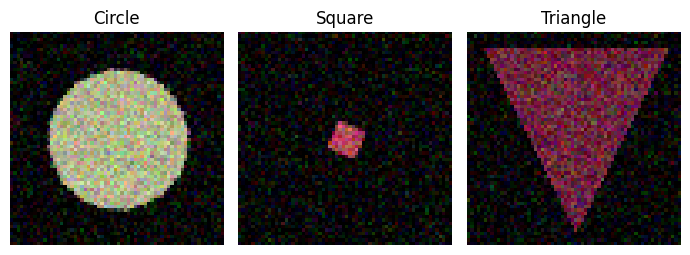

In [1]:
import numpy as np
import cv2
import random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, Flatten, MaxPooling2D, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from collections import Counter

def create_shape(shape, color, img_size=64):
  img = np.zeros((img_size, img_size, 3), dtype=np.uint8)
  color = (int(color[0] * 255), int(color[1] * 255), int(color[2] * 255))

  # Randomizing size of the shape
  size = random.randint(img_size // 8, img_size // 2)
  center = (img_size // 2, img_size // 2)

  if shape == 'circle':
    cv2.circle(img, center, size, color, -1)

  elif shape == 'square':
    start = center[0] - size // 2
    end = center[0] + size // 2
    cv2.rectangle(img, (start, start), (end, end), color, -1)

  elif shape == 'triangle':
    points = np.array([[center[0], center[1] - size],
                      [center[0] - size, center[1] + size],
                      [center[0] + size, center[1] + size]], dtype=np.int32)
    cv2.drawContours(img, [points], 0, color, -1)

  # Rotation
  angle = random.randint(0, 360)
  M = cv2.getRotationMatrix2D(center, angle, 1)
  img = cv2.warpAffine(img, M, (img_size, img_size))

  # Occlusion
  if random.random() < 0.2: # 20% chance of occlusion
    x, y = random.randint(0, img_size // 2), random.randint(0, img_size // 2)
    w, h = random.randint(img_size // 4, img_size // 2), random.randint(img_size // 4, img_size // 2)
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 0, 0), -1)

  # Adding noise
  noise = np.random.normal(loc=0, scale=25, size=(img_size, img_size, 3))
  img = img + noise
  img = np.clip(img, 0, 255).astype(np.uint8)

  return img

SEED = 42
SHAPES = ("circle", "square", "triangle")
tf.keras.utils.set_random_seed(SEED)

images = np.stack([
    create_shape(shape, (random.random(), random.random(), random.random()))
    for shape in SHAPES
    for _ in range(100)
])
labels = np.repeat(np.arange(len(SHAPES)), 100)

train_images, test_images, train_labels, test_labels = train_test_split(
    images, labels, test_size=0.2, random_state=SEED, stratify=labels
)
train_images, val_images, train_labels, val_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=SEED,
    stratify=train_labels
)

fig, axes = plt.subplots(1, len(SHAPES), figsize=(7, 2.6))
for class_id, axis in enumerate(axes):
    example = test_images[np.flatnonzero(test_labels == class_id)[0]]
    axis.imshow(cv2.cvtColor(example, cv2.COLOR_BGR2RGB))
    axis.set_title(SHAPES[class_id].capitalize())
    axis.axis("off")
fig.tight_layout()
plt.show()

## Train the CNN

Epoch 1/20


6/6 - 1s - 226ms/step - accuracy: 0.3125 - loss: 1.1043 - val_accuracy: 0.4375 - val_loss: 0.9638


Epoch 2/20


6/6 - 0s - 49ms/step - accuracy: 0.6146 - loss: 0.9093 - val_accuracy: 0.5833 - val_loss: 0.9297


Epoch 3/20


6/6 - 0s - 46ms/step - accuracy: 0.6406 - loss: 0.8877 - val_accuracy: 0.6458 - val_loss: 0.8757


... (30 outputs left out)

Epoch 19/20


6/6 - 0s - 52ms/step - accuracy: 0.9427 - loss: 0.1739 - val_accuracy: 0.7083 - val_loss: 0.8246


Epoch 20/20


6/6 - 0s - 49ms/step - accuracy: 0.9323 - loss: 0.1759 - val_accuracy: 0.7083 - val_loss: 0.9619


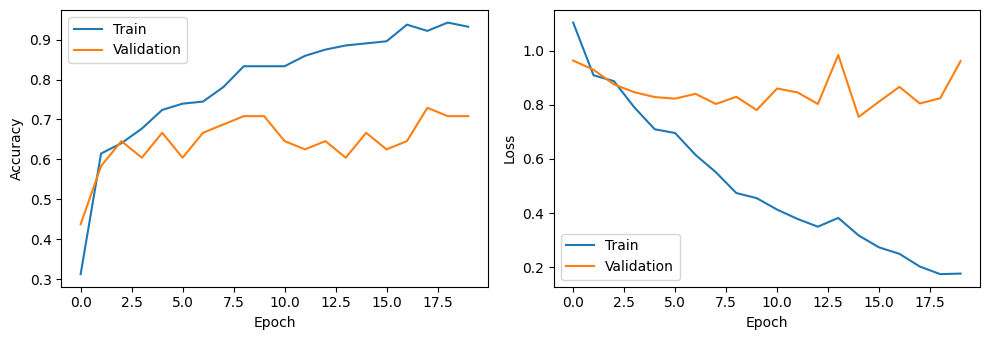

In [2]:
def normalize(images):
    return images.astype(np.float32) / 255.0

model = Sequential([
    Input(shape=(64, 64, 3)),
    Conv2D(32, kernel_size=3, activation="relu"),
    MaxPooling2D(pool_size=2),
    Conv2D(64, kernel_size=3, activation="relu"),
    MaxPooling2D(pool_size=2),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(len(SHAPES), activation="softmax"),
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history = model.fit(
    normalize(train_images), to_categorical(train_labels, len(SHAPES)),
    validation_data=(normalize(val_images), to_categorical(val_labels, len(SHAPES))),
    epochs=20, batch_size=32, verbose=2,
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, metric in zip(axes, ("accuracy", "loss")):
    axis.plot(history.history[metric], label="Train")
    axis.plot(history.history["val_" + metric], label="Validation")
    axis.set(xlabel="Epoch", ylabel=metric.capitalize())
    axis.legend()
fig.tight_layout()
plt.show()

## Evaluate both methods on the same test set

The OpenCV baseline uses Canny edges and counts the vertices of approximated contours. An unknown prediction counts as incorrect.

In [3]:
def predict_shape(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 30, 150)
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    guesses = []
    for contour in contours:
        perimeter = cv2.arcLength(contour, True)
        vertices = len(cv2.approxPolyDP(contour, 0.04 * perimeter, True))
        if vertices == 3:
            guesses.append("triangle")
        elif vertices == 4:
            guesses.append("square")
        elif vertices > 4:
            guesses.append("circle")
        else:
            guesses.append("unknown")
    return Counter(guesses).most_common(1)[0][0] if guesses else "unknown"

assert np.bincount(test_labels).tolist() == [20, 20, 20]
expected = np.asarray(SHAPES)[test_labels]
cnn = np.asarray(SHAPES)[model.predict(normalize(test_images), verbose=0).argmax(axis=1)]
opencv = np.array([predict_shape(img) for img in test_images])
for name, predictions in (("CNN", cnn), ("OpenCV", opencv)):
    hits = int(np.count_nonzero(predictions == expected))
    print(f"{name}: {hits}/{len(expected)} ({hits / len(expected):.1%})")

CNN: 46/60 (76.7%)
OpenCV: 42/60 (70.0%)


## Optional ImageNet demonstration

Set a local image path to run VGG16 and ResNet50 on a separate example. This downloads pretrained weights and is independent of the synthetic benchmark.

In [4]:
IMAGE_PATH = ""  # Set a local path to run the optional ImageNet demo.

if IMAGE_PATH:
    from tensorflow.keras.applications import resnet50, vgg16
    from tensorflow.keras.utils import img_to_array, load_img

    image_array = img_to_array(load_img(IMAGE_PATH, target_size=(224, 224)))
    batch = np.expand_dims(image_array, axis=0)
    for name, classifier, preprocess, decode in (
        ("VGG16", vgg16.VGG16, vgg16.preprocess_input, vgg16.decode_predictions),
        ("ResNet50", resnet50.ResNet50, resnet50.preprocess_input, resnet50.decode_predictions),
    ):
        predictions = classifier(weights="imagenet").predict(preprocess(batch.copy()), verbose=0)
        _, label, confidence = decode(predictions, top=1)[0][0]
        print(f"{name}: {label} ({confidence:.1%})")